# 04_eda: exploratory analysis
Aggregates only: no raw ticket rows are printed. Input: data/processed/itsm_clean.pkl (from 03_cleaning). The findings here set the modelling window and the Track 1 split used in 05_split_features, and the Track 2 series in 07_track2_volume.

## 1. Setup and load the clean data

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append("../src")

df = pd.read_pickle("../data/processed/itsm_clean.pkl")
print(df.shape)

(46606, 26)


## 2. Columns added and removed during cleaning

In [2]:
raw_cols = pd.read_csv("../data/raw/itsm_raw.csv", nrows=0).columns
print("Added  :", sorted(set(df.columns) - set(raw_cols)))
print("Removed:", sorted(set(raw_cols) - set(df.columns)))

Added  : ['Elapsed_hrs', 'Has_Related_Change', 'Has_Reopen_Time']
Removed: ['Alert_Status', 'number_cnt']


## 3. Target balance: Priority and the High (P1+P2) share

In [3]:
lab = df[df["Priority"].notna()]
print(len(lab))
print(lab["Priority"].astype(int).value_counts().sort_index())
print("High (P1+P2) share:", round(lab["Priority"].isin([1, 2]).mean() * 100, 2), "%")

45226
Priority
1        3
2      697
3     5323
4    22717
5    16486
Name: count, dtype: int64
High (P1+P2) share: 1.55 %


## 4. Tickets opened per month (dashed line: start of the close-date window)

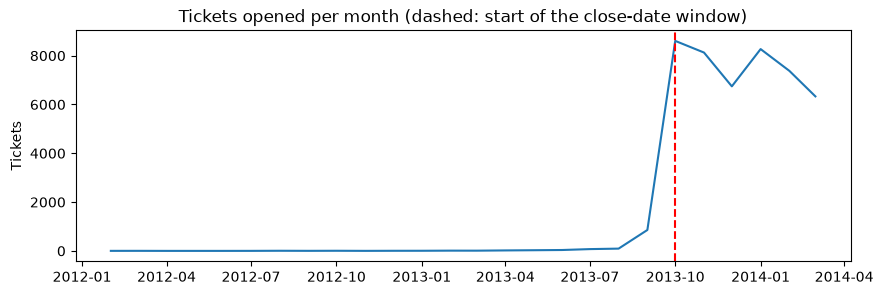

count      26.0
mean     1793.0
std      3260.0
min         0.0
25%         2.0
50%        10.0
75%       666.0
max      8606.0
dtype: float64


In [4]:
monthly = df.set_index("Open_Time").resample("MS").size()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(monthly.index, monthly.values)
ax.axvline(pd.Timestamp("2013-10-01"), color="red", linestyle="--")
ax.set_title("Tickets opened per month (dashed: start of the close-date window)")
ax.set_ylabel("Tickets")
plt.show()
print(monthly.describe().round(0))

## 5. Main categories: CI_Cat, Category and Closure_Code

In [5]:
for c in ["CI_Cat", "Category", "Closure_Code"]:
    print(df[c].value_counts().head(8), "\n")

CI_Cat
application       32900
subapplication     7782
computer           3643
storage             703
hardware            442
software            333
database            214
displaydevice       212
Name: count, dtype: int64 

Category
incident                   37748
request for information     8846
complaint                     11
request for change             1
Name: count, dtype: int64 

Closure_Code
Other                           16470
Software                        13027
User error                       3554
No error - works as designed     3530
Hardware                         2999
Data                             2209
Unknown                          1590
Operator error                   1539
Name: count, dtype: int64 



## 6. Elapsed hours (display only: clipped at the 99th percentile, the data is unchanged)

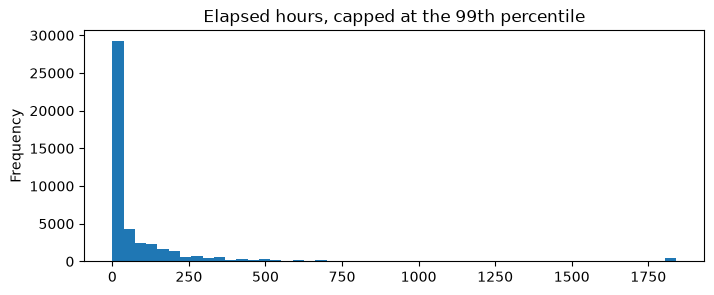

In [6]:
cap = df["Elapsed_hrs"].quantile(0.99)
df["Elapsed_hrs"].clip(upper=cap).plot.hist(bins=50, figsize=(8, 3), title="Elapsed hours, capped at the 99th percentile")
plt.show()

## 7. Opened and closed per month: the extract is cut by close date

In [7]:
closed = df.set_index("Close_Time").resample("MS").size()
both = pd.DataFrame({"opened": monthly, "closed": closed}).fillna(0).astype(int)
print(both.loc["2013-07":])
print("Share opened Oct 2013 or later:", round((df["Open_Time"] >= "2013-10-01").mean() * 100, 1), "%")
print("Share closed Oct 2013 or later:", round((df["Close_Time"] >= "2013-10-01").mean() * 100, 1), "%")
print("Close_Time range:", df["Close_Time"].min().date(), "to", df["Close_Time"].max().date())

            opened  closed
2013-07-01      73       0
2013-08-01      93       0
2013-09-01     857       0
2013-10-01    8606    8544
2013-11-01    8128    8052
2013-12-01    6743    7013
2014-01-01    8270    8210
2014-02-01    7377    7542
2014-03-01    6332    7245
Share opened Oct 2013 or later: 97.5 %
Share closed Oct 2013 or later: 100.0 %
Close_Time range: 2013-10-01 to 2014-03-31


## 8. High-priority tickets per month

In [8]:
tot = lab.set_index("Open_Time").resample("MS").size()
hi = lab[lab["Priority"].isin([1, 2])].set_index("Open_Time").resample("MS").size()
print(pd.DataFrame({"labelled": tot, "high": hi}).fillna(0).astype(int).loc["2013-09":])

            labelled  high
Open_Time                 
2013-09-01       831     1
2013-10-01      8344   178
2013-11-01      7901   133
2013-12-01      6551   130
2014-01-01      8049   100
2014-02-01      7154    79
2014-03-01      6113    79


## 9. Survivorship: tickets opened before October 2013

In [9]:
pre = lab[lab["Open_Time"] < "2013-10-01"]
win = lab[lab["Open_Time"] >= "2013-10-01"]
for name, part in [("Opened before Oct 2013", pre), ("Opened Oct 2013 onward", win)]:
    hi = part["Priority"].isin([1, 2]).sum()
    print(f"{name}: labelled {len(part)}, High {hi}, rate {hi / len(part) * 100:.2f}%")

Opened before Oct 2013: labelled 1114, High 1, rate 0.09%
Opened Oct 2013 onward: labelled 44112, High 699, rate 1.58%


### Findings: why the extract is not three years of data
1. The 1,150 tickets opened before October 2013 are the backlog still open on 1 October (September 857, August 93, July 73, about 127 earlier). They are in the extract only because they closed inside the window, so they are the slow tickets. That is survivorship bias: High-priority tickets get fixed fast and almost never appear there (1 High in 1,114 labelled, 0.09%, against 699 in 44,112, 1.58%, from October onward).
2. The close-date window covers 182 days (1 October 2013 to 31 March 2014); after the end is trimmed (section 11) there are 167 days of opened tickets. Quarterly forecasting would rest on 2 data points and annual forecasting on none, so only daily or weekly forecasts are supported.
3. The High rate drifts down over the window (2.13% in October to 1.10% and 1.29% in February and March), so a threshold tuned on the early months will over-alert later.
4. With 79 High tickets in a single month, one-month estimates are noisy.

## 10. Tickets not marked Closed

In [10]:
print(df.loc[df["Status"] != "Closed", ["Open_Time", "Close_Time"]].agg(["min", "max"]))

              Open_Time          Close_Time
min 2013-10-08 13:10:00 2013-10-09 08:55:00
max 2013-10-28 15:03:00 2013-10-29 17:01:00


## 11. End of the window: is it right-censored?
Tickets opened in late March and still open on 31 March are missing from the extract. Weekly counts, p90 elapsed hours and the share of tickets over 72 hours show whether the last weeks are incomplete. The weekly High counts show the rate drifting, and the last line compares how fast High and other tickets close.

In [11]:
w = df[df["Open_Time"] >= "2013-10-01"].copy()
w["week"] = w["Open_Time"].dt.to_period("W")

tail = w.groupby("week").agg(
    opened=("Incident_ID", "size"),
    median_hrs=("Elapsed_hrs", "median"),
    p90_hrs=("Elapsed_hrs", lambda s: s.quantile(0.9)),
    share_over_72h=("Elapsed_hrs", lambda s: (s > 72).mean() * 100),
)
print(tail.round(1).tail(10))

lab_w = w[w["Priority"].notna()].copy()
lab_w["high"] = lab_w["Priority"].isin([1, 2])
print(lab_w.groupby("week")["high"].agg(["size", "sum"]).tail(10))
print(lab_w.groupby("high")["Elapsed_hrs"].median().round(1))

                       opened  median_hrs  p90_hrs  share_over_72h
week                                                              
2014-01-27/2014-02-02    2098         7.7    216.1            24.0
2014-02-03/2014-02-09    2111        16.8    215.2            26.4
2014-02-10/2014-02-16    1749        18.0    220.8            27.4
2014-02-17/2014-02-23    1867        15.9    205.2            26.7
2014-02-24/2014-03-02    1656         7.6    190.9            23.8
2014-03-03/2014-03-09    1540        16.0    174.5            26.4
2014-03-10/2014-03-16    1627        11.0    170.6            24.2
2014-03-17/2014-03-23    1514         6.0    140.9            19.2
2014-03-24/2014-03-30    1421         3.9     71.4             9.9
2014-03-31/2014-04-06     217         1.8      4.8             0.0
                       size  sum
week                            
2014-01-27/2014-02-02  2036   25
2014-02-03/2014-02-09  2059   25
2014-02-10/2014-02-16  1698   21
2014-02-17/2014-02-23  1799   1

### Findings: the end of the window is right-censored
1. The share of tickets over 72 hours sits at 24 to 27% for seven weeks, then falls to 19.2%, 9.9% and 0.0% from the week of 17 March. Part of the drop at the very end is built in: a ticket opened on 29 or 30 March cannot exceed 72 hours when the data stops on 31 March. Median elapsed time is too unstable to use for this check (it swings between 7.6 and 18.0 hours in ordinary weeks); p90 and the share over 72 hours are steadier.
2. High tickets close much faster (median 3.8 hours against 18.1 for the rest), so tickets still open on 31 March are mostly slow, non-High tickets. That can inflate the late-window High rate: 23 of 1,371 labelled tickets (1.68%) in the week of 24 March, against 140 of 12,259 (1.14%) over the seven plateau weeks.

### Decision
End the modelling window before 17 March 2014.

## 12. Modelling window and Track 1 split sizes

In [12]:
start = pd.Timestamp("2013-10-01")
cut = pd.Timestamp("2014-03-17")
mw = df[(df["Open_Time"] >= start) & (df["Open_Time"] < cut)]
print("Modelling window rows:", len(mw), "| opened from cut-off:", int((df["Open_Time"] >= cut).sum()))

lab_m = mw[mw["Priority"].notna()]
for name, a, b in [("Train/tune Oct-Jan", "2013-10-01", "2014-02-01"),
                   ("Test Feb to 16 Mar", "2014-02-01", "2014-03-17")]:
    part = lab_m[(lab_m["Open_Time"] >= a) & (lab_m["Open_Time"] < b)]
    hi = part["Priority"].isin([1, 2]).sum()
    print(f"{name}: labelled {len(part)}, High {hi}, rate {hi / len(part) * 100:.2f}%")

Modelling window rows: 42304 | opened from cut-off: 3152
Train/tune Oct-Jan: labelled 30845, High 541, rate 1.75%
Test Feb to 16 Mar: labelled 10229, High 115, rate 1.12%


## Decisions from this notebook
1. Modelling window: tickets opened on or after 2013-10-01 and before 2014-03-17 (42,304 rows; 41,074 have a priority label).
2. Track 1 split: train and tune on October to January (30,845 labelled tickets, 541 High); test 1 February to 16 March (10,229 labelled, 115 High). The test period is scored once for the headline result.
3. Track 2: daily and weekly forecasts only (about 24 weeks of history).
4. Tickets opened before October 2013 are excluded from modelling (survivor backlog).